In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [ ]:
!pip install kagglehub

In [3]:
# Loading the dataset

import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 117M/117M [10:26<00:00, 196kB/s]  

Extracting files...


Path to dataset files: C:\Users\ASUS\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


Part 1: Understanding Product Categories

Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

2. Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [10]:
# Importing the dataset

df = pd.read_csv(r"C:\Users\ASUS\Desktop\Ironhack\Labs\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")

In [11]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [21]:
df["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [28]:
(df["category"].value_counts(normalize=True) * 100).round(2)

category
Sports & Outdoors                         34.22
Beauty                                     0.79
Handmade Clothing, Shoes & Accessories     0.79
Bath & Body                                0.78
Birthday Gifts                             0.78
                                          ...  
Motorbike Chassis                          0.00
Alexa Built-In Devices                     0.00
Plugs                                      0.00
Smart Home Security & Lighting             0.00
Smart Speakers                             0.00
Name: proportion, Length: 296, dtype: float64

In [29]:
category_summary = pd.DataFrame({
    "Listings": df["category"].value_counts(),
    "Percentage": (df["category"].value_counts(normalize=True) * 100).round(2)
})

category_summary.head(10)

,Listings,Percentage
category,,
Sports & Outdoors,836265,34.22
Beauty,19312,0.79
"Handmade Clothing, Shoes & Accessories",19229,0.79
Bath & Body,19092,0.78
Birthday Gifts,18978,0.78
Manicure & Pedicure Products,18940,0.78
Skin Care,18769,0.77
Make-up,18756,0.77
Hair Care,18735,0.77


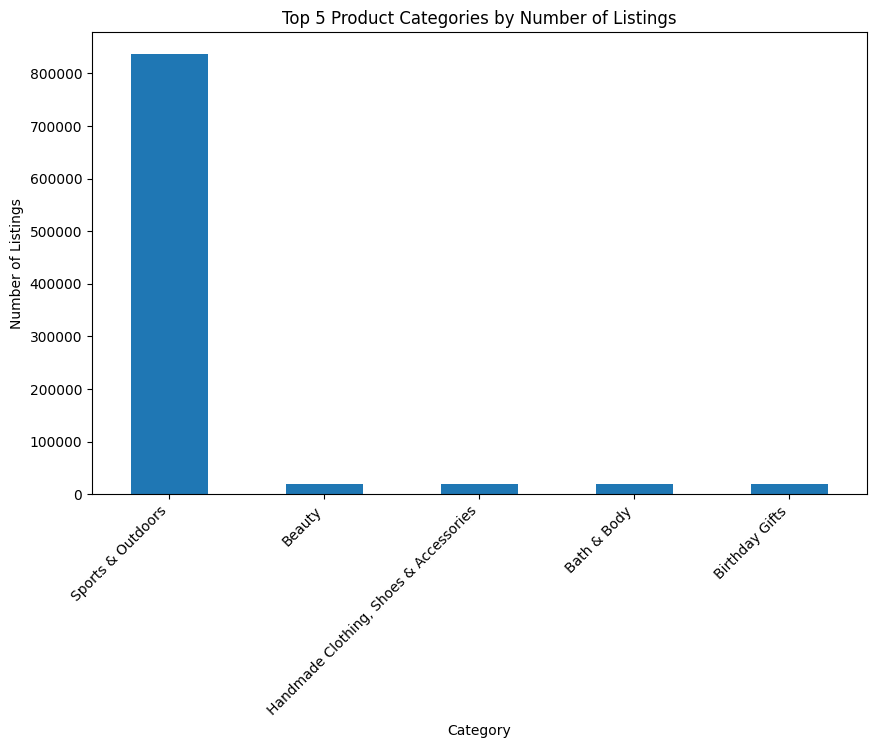

In [33]:
top5 = df["category"].value_counts().head(5)

plt.figure(figsize=(10,6))
top5.plot(kind="bar")
plt.title("Top 5 Product Categories by Number of Listings")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45, ha="right")
plt.show()

In [39]:
category_counts = df["category"].value_counts()

print(category_counts.head())

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


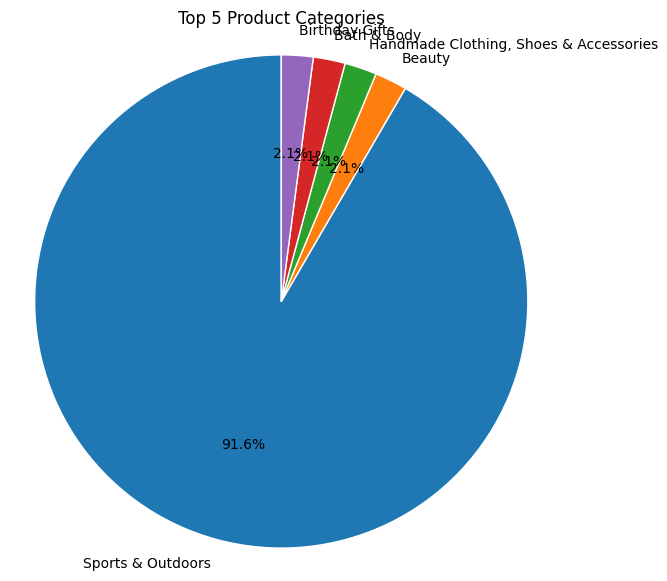

In [42]:
# Keep only the top 5 categories
top5 = category_counts.head(5)

plt.figure(figsize=(7,7))
plt.pie(
    top5,
    labels=top5.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'white'}
)

plt.title("Top 5 Product Categories")
plt.axis('equal')
plt.show()

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

3. Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [43]:
# Mean
mean_price = df["price"].mean()

# Median
median_price = df["price"].median()

# Mode
mode_price = df["price"].mode()[0]

print(f"Mean: {mean_price:.2f}")
print(f"Median: {median_price:.2f}")
print(f"Mode: {mode_price:.2f}")

Mean: 89.24
Median: 19.09
Mode: 9.99


In [ ]:
# Mean: average product price.
# Median: middle price (less affected by outliers).
# Mode: most common price.

In [44]:
variance = df["price"].var()
std = df["price"].std()
price_range = df["price"].max() - df["price"].min()
iqr = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print(f"Variance: {variance:.2f}")
print(f"Standard deviation: {std:.2f}")
print(f"Range: {price_range:.2f}")
print(f"IQR: {iqr:.2f}")

Variance: 119445.49
Standard deviation: 345.61
Range: 100000.00
IQR: 36.00


In [ ]:
# Large values of standard deviation, range and IQR indicate that prices vary considerably.

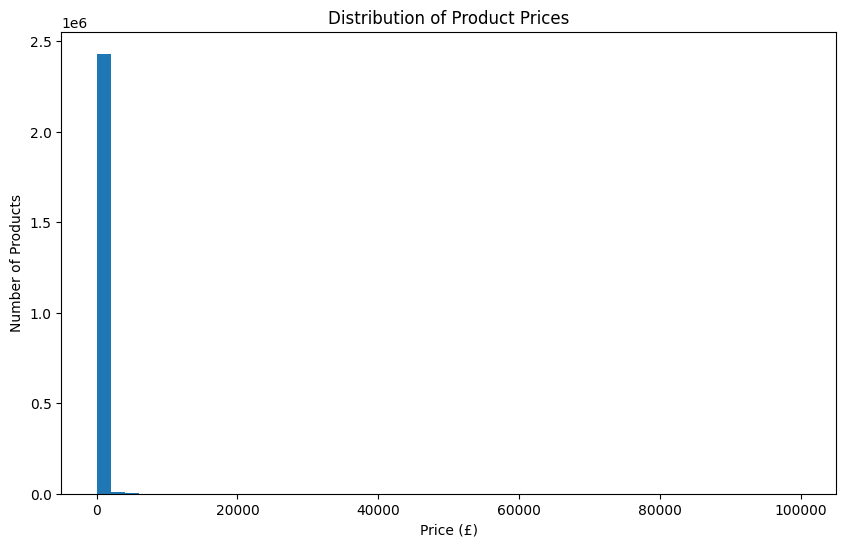

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.hist(df["price"], bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.show()

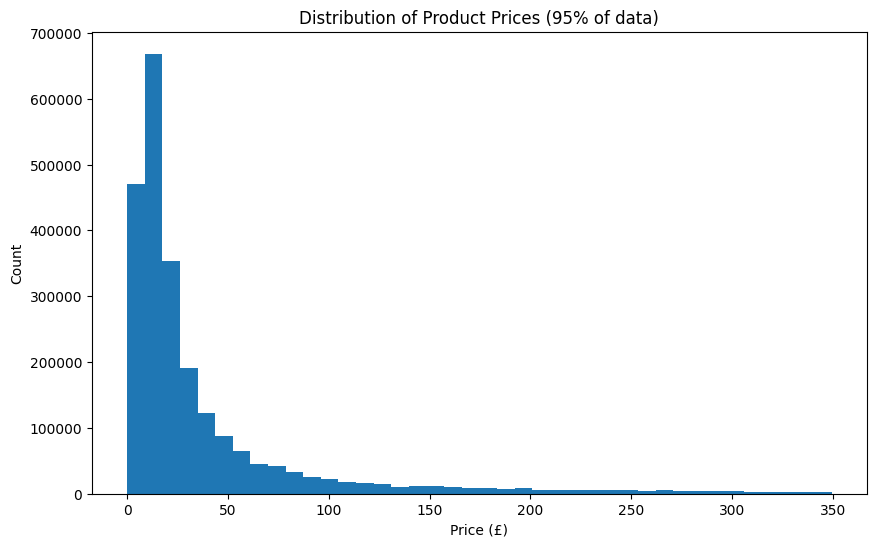

In [46]:
upper_limit = df["price"].quantile(0.95)

plt.figure(figsize=(10,6))

plt.hist(
    df[df["price"] <= upper_limit]["price"],
    bins=40
)

plt.title("Distribution of Product Prices (95% of data)")
plt.xlabel("Price (£)")
plt.ylabel("Count")

plt.show()

The histogram is highly right-skewed due to a small number of very expensive products. These outliers compress the majority of observations into a narrow area, making the distribution difficult to interpret. 

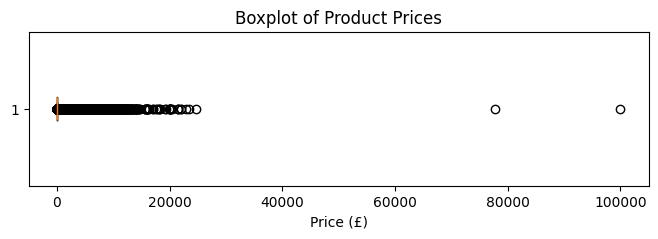

In [49]:
plt.figure(figsize=(8,2))

plt.boxplot(df["price"], vert=False)

plt.title("Boxplot of Product Prices")
plt.xlabel("Price (£)")

plt.show()

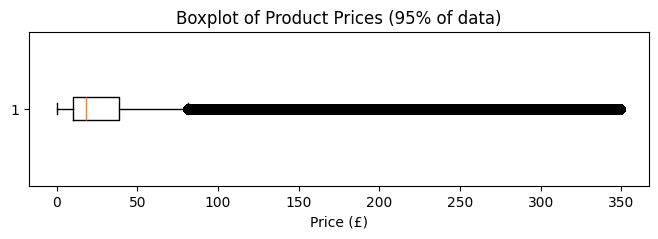

In [50]:
plt.figure(figsize=(8,2))

plt.boxplot(
    df[df["price"] <= upper_limit]["price"],
    vert=False
)

plt.title("Boxplot of Product Prices (95% of data)")
plt.xlabel("Price (£)")

plt.show()

The boxplot reveals numerous high-price outliers, indicating that while most products are relatively inexpensive, a small number of premium products are priced substantially higher than the rest.

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

2. Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

3. Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

4. Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [52]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [56]:
df["stars"].isna().sum()

np.int64(0)

In [65]:
# Keep only products with an actual rating
stars = df[df["stars"] > 0]["stars"]

In [66]:
stars = df.loc[df["stars"] != 0, "stars"]

In [67]:
# Centrality
print(stars.mean())
print(stars.median())
print(stars.mode())

# Dispersion
print(stars.var())
print(stars.std())
print(stars.quantile(0.75) - stars.quantile(0.25))

# Shape
print(stars.skew())
print(stars.kurt())

4.319160762226911
4.4
0    4.5
Name: stars, dtype: float64
0.3083433752387284
0.5552867504620729
0.5
-2.379568112212799
9.78193769066435


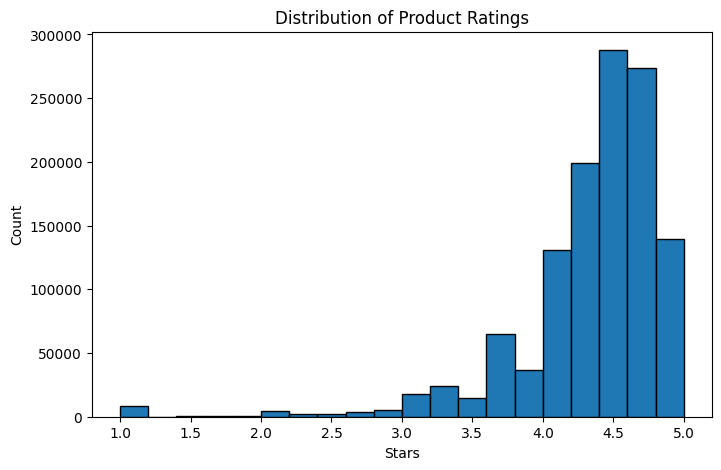

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(stars, bins=20, edgecolor="black")

plt.title("Distribution of Product Ratings")
plt.xlabel("Stars")
plt.ylabel("Count")

plt.show()

The dataset contains a large number of products with a stars value of 0.0. Since Amazon products cannot receive a 0-star rating, these values likely represent products that have not yet been rated. To analyze customer ratings accurately, these observations were excluded from the statistical analysis and visualizations.

Outcomes:

Statistic	Value	Interpretation
Mean	    4.32	The average product rating is 4.32 stars, indicating that customers generally rate products positively.
Median	    4.4	    Half of the rated products have a rating below 4.4 stars and half above. The median being slightly higher than the mean suggests a few lower-rated products pull the average down.
Mode	    4.5	    The most common rating is 4.5 stars, reinforcing that many products receive high customer ratings.

Measures of Dispersion
Statistic	        Value	Interpretation
Variance	        0.31	Ratings show relatively little variability.
Standard deviation	0.56	Most ratings are within about ±0.56 stars of the mean, indicating fairly consistent customer feedback.
IQR	                0.5	    The middle 50% of ratings span only 0.5 stars, meaning that most products are rated within a narrow range.

Shape of the Distribution
Statistic	Value	Interpretation
Skewness	-2.38	The distribution is strongly negatively skewed. Most products have high ratings (around 4–5 stars), while relatively few products receive low ratings.
Kurtosis	9.78	The distribution is highly leptokurtic, meaning it has a sharp peak and heavy tails compared to a normal distribution. This occurs because a large proportion of products are clustered around ratings of 4.5–5.0 stars, with relatively few observations elsewhere.